# All Models Evaluation Report

This notebook loads saved FNEWS experiment artifacts and evaluates every matched text, image, and multimodal model with precision, recall, Macro F1, weighted F1, accuracy, ROC-AUC, Brier score, confusion matrices, ROC curves, threshold curves, calibration curves, bootstrap intervals, and paired model comparison.

It does **not** retrain models and does **not** use the official Fakeddit test split.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path('..').resolve()
SRC = PROJECT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from fnews.ml.metrics.calibration import threshold_metrics  # noqa: E402
from fnews.ml.metrics.classification import (  # noqa: E402
    binary_classification_metrics,
    confusion_matrix_binary,
    roc_curve_manual,
)

REPORT = PROJECT / 'reports' / 'experiments' / 'milestone8'
clean_predictions = pd.read_parquet(REPORT / 'clean_predictions.parquet')
original_predictions = pd.read_parquet(REPORT / 'original_predictions.parquet')
comparison = pd.read_csv(REPORT / 'clean_comparison.csv')

TEXT_BASELINE = PROJECT / 'reports' / 'experiments' / 'text_linear_50k_multiseed' / 'aggregate_metrics.csv'
NEURAL_TEXT_COMPARISON = PROJECT / 'reports' / 'experiments' / 'neural_text' / 'comparison.csv'
text_baselines = pd.read_csv(TEXT_BASELINE)
neural_text_comparison = pd.read_csv(NEURAL_TEXT_COMPARISON)


MODEL_NAMES = [
    'text_encoder_classifier',
    'image_cnn_classifier',
    'text_repr_same_head',
    'image_repr_same_head',
    'concat_fusion',
    'similarity_fusion',
    'gated_fusion',
]
DISPLAY_NAMES = {
    'text_encoder_classifier': 'Text encoder classifier',
    'image_cnn_classifier': 'Image CNN classifier',
    'text_repr_same_head': 'Text representation head',
    'image_repr_same_head': 'Image representation head',
    'concat_fusion': 'Concat fusion',
    'similarity_fusion': 'Similarity fusion',
    'gated_fusion': 'Gated diagnostic',
}

comparison

,model,train_n,validation_n,accuracy,precision,recall,macro_f1,weighted_f1,roc_auc,brier_score,manifest
0,text_encoder_classifier,2846,957,0.689655,0.620991,0.560526,0.669921,0.686535,0.764839,0.215703,original
1,image_cnn_classifier,2846,957,0.602926,0.000000,0.000000,0.376141,0.453570,0.396826,0.243823,original
2,text_repr_same_head,2846,957,0.698015,0.624658,0.600000,0.682430,0.696912,0.765144,0.242200,original
3,image_repr_same_head,2846,957,0.602926,0.000000,0.000000,0.376141,0.453570,0.522996,0.238392,original
4,concat_fusion,2846,957,0.698015,0.623306,0.605263,0.683042,0.697223,0.764645,0.240822,original
5,similarity_fusion,2846,957,0.698015,0.623978,0.602632,0.682738,0.697069,0.764412,0.241137,original
6,gated_fusion,2846,957,0.694880,0.618919,0.602632,0.679904,0.694156,0.765621,0.231749,original
7,text_encoder_classifier,2683,957,0.681296,0.600000,0.592105,0.666434,0.680928,0.746550,0.223655,clean
8,image_cnn_classifier,2683,957,0.602926,0.000000,0.000000,0.376141,0.453570,0.415105,0.243235,clean
9,text_repr_same_head,2683,957,0.690700,0.608247,0.621053,0.678147,0.691231,0.746221,0.251245,clean


## Text-Only Baseline Models

These are the earlier text-only evaluations you asked about: **TF-IDF + Logistic Regression**, **TF-IDF + Linear SVM**, and the **Neural Text Embedding Model**.

Important: these rows are evaluated on the larger official validation text split, not the smaller matched local-image validation set. That is why they are shown separately from the multimodal chart.

In [2]:
baseline_rows = []
for _, row in text_baselines.iterrows():
    baseline_rows.append({
        'model': 'TF-IDF + Linear SVM' if row['model'] == 'linear_svm' else 'TF-IDF + Logistic Regression',
        'evaluation_set': 'official validation text split',
        'runs': int(row['n_runs']),
        'accuracy': row['accuracy_mean'],
        'precision': row['precision_mean'],
        'recall': row['recall_mean'],
        'macro_f1': row['macro_f1_mean'],
        'weighted_f1': row['weighted_f1_mean'],
        'roc_auc': row['roc_auc_mean'],
        'brier_score': row['brier_score_mean'],
    })
for _, row in neural_text_comparison.iterrows():
    if row['model'] == 'Trainable embedding mean-pool 10k':
        baseline_rows.append({
            'model': 'Neural Text Embedding Model',
            'evaluation_set': 'official validation text split',
            'runs': 1,
            'accuracy': row['accuracy'],
            'precision': np.nan,
            'recall': np.nan,
            'macro_f1': row['macro_f1'],
            'weighted_f1': row['weighted_f1'],
            'roc_auc': row['roc_auc'],
            'brier_score': np.nan,
        })
text_baseline_summary = pd.DataFrame(baseline_rows)
text_baseline_summary.sort_values('macro_f1', ascending=False).reset_index(drop=True)

,model,evaluation_set,runs,accuracy,precision,recall,macro_f1,weighted_f1,roc_auc,brier_score
0,Neural Text Embedding Model,official validation text split,1,0.733797,NaN,NaN,0.721144,0.733858,0.799603,NaN
1,TF-IDF + Logistic Regression,official validation text split,3,0.650742,0.752809,0.16568,0.520864,0.574256,0.761973,0.211492
2,TF-IDF + Linear SVM,official validation text split,3,0.607024,0.000000,0.00000,0.377732,0.458584,0.755589,0.252187


## Text Baseline Bar Chart

This chart answers: how did the pure text baselines compare before the matched multimodal experiments?

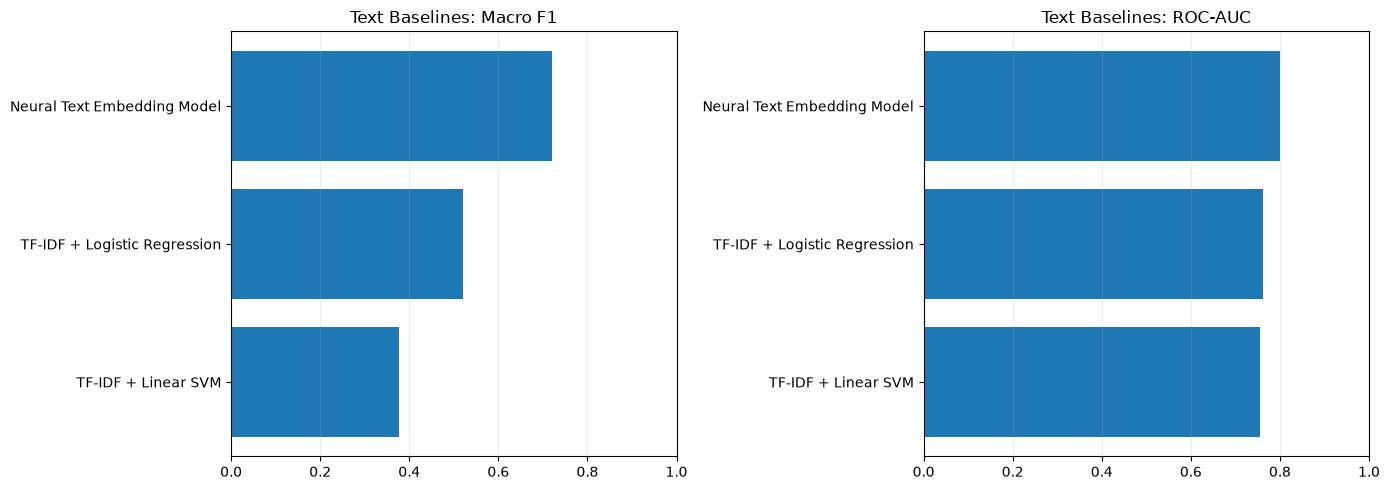

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordered = text_baseline_summary.sort_values('macro_f1')
axes[0].barh(ordered['model'], ordered['macro_f1'])
axes[0].set_title('Text Baselines: Macro F1')
axes[0].set_xlim(0, 1)
axes[0].grid(axis='x', alpha=0.25)

ordered_auc = text_baseline_summary.sort_values('roc_auc')
axes[1].barh(ordered_auc['model'], ordered_auc['roc_auc'])
axes[1].set_title('Text Baselines: ROC-AUC')
axes[1].set_xlim(0, 1)
axes[1].grid(axis='x', alpha=0.25)
plt.tight_layout()

## Why These Are Separate From The Multimodal Chart

The TF-IDF and neural-text baseline rows above use the broader text validation setting. The multimodal rows below use only examples that have both valid text and a downloaded local image.

So the fair multimodal question is answered by the matched rows below, while the text-baseline section shows the earlier model-development progression.

## Metric Summary

The table below compares the original matched manifest and the leakage-reduced clean manifest. The clean manifest is the more reliable evaluation setting because training rows that duplicated validation content were removed.

In [4]:
metric_cols = ['manifest', 'model', 'train_n', 'validation_n', 'accuracy', 'precision', 'recall', 'macro_f1', 'weighted_f1', 'roc_auc', 'brier_score']
summary = comparison[metric_cols].copy()
summary['model'] = summary['model'].map(DISPLAY_NAMES)
summary.sort_values(['manifest', 'macro_f1'], ascending=[True, False]).reset_index(drop=True)

,manifest,model,train_n,validation_n,accuracy,precision,recall,macro_f1,weighted_f1,roc_auc,brier_score
0,clean,Text representation head,2683,957,0.690700,0.608247,0.621053,0.678147,0.691231,0.746221,0.251245
1,clean,Similarity fusion,2683,957,0.688610,0.603535,0.628947,0.677058,0.689631,0.744719,0.249127
2,clean,Gated diagnostic,2683,957,0.688610,0.607330,0.610526,0.675122,0.688749,0.747364,0.243606
3,clean,Concat fusion,2683,957,0.686520,0.601523,0.623684,0.674623,0.687431,0.746069,0.248963
4,clean,Text encoder classifier,2683,957,0.681296,0.600000,0.592105,0.666434,0.680928,0.746550,0.223655
5,clean,Image representation head,2683,957,0.603971,1.000000,0.002632,0.379011,0.455950,0.476051,0.240654
6,clean,Image CNN classifier,2683,957,0.602926,0.000000,0.000000,0.376141,0.453570,0.415105,0.243235
7,original,Concat fusion,2846,957,0.698015,0.623306,0.605263,0.683042,0.697223,0.764645,0.240822
8,original,Similarity fusion,2846,957,0.698015,0.623978,0.602632,0.682738,0.697069,0.764412,0.241137
9,original,Text representation head,2846,957,0.698015,0.624658,0.600000,0.682430,0.696912,0.765144,0.242200


## Clean Evaluation Metrics

This is the most important table for reporting current results.

In [5]:
clean_summary = comparison[comparison['manifest'] == 'clean'][metric_cols].copy()
clean_summary['model'] = clean_summary['model'].map(DISPLAY_NAMES)
clean_summary.sort_values('macro_f1', ascending=False).reset_index(drop=True)

,manifest,model,train_n,validation_n,accuracy,precision,recall,macro_f1,weighted_f1,roc_auc,brier_score
0,clean,Text representation head,2683,957,0.690700,0.608247,0.621053,0.678147,0.691231,0.746221,0.251245
1,clean,Similarity fusion,2683,957,0.688610,0.603535,0.628947,0.677058,0.689631,0.744719,0.249127
2,clean,Gated diagnostic,2683,957,0.688610,0.607330,0.610526,0.675122,0.688749,0.747364,0.243606
3,clean,Concat fusion,2683,957,0.686520,0.601523,0.623684,0.674623,0.687431,0.746069,0.248963
4,clean,Text encoder classifier,2683,957,0.681296,0.600000,0.592105,0.666434,0.680928,0.746550,0.223655
5,clean,Image representation head,2683,957,0.603971,1.000000,0.002632,0.379011,0.455950,0.476051,0.240654
6,clean,Image CNN classifier,2683,957,0.602926,0.000000,0.000000,0.376141,0.453570,0.415105,0.243235


## Metric Bar Charts

These plots make it easy to compare F1, precision, recall, accuracy, ROC-AUC, and Brier score across all clean matched models.

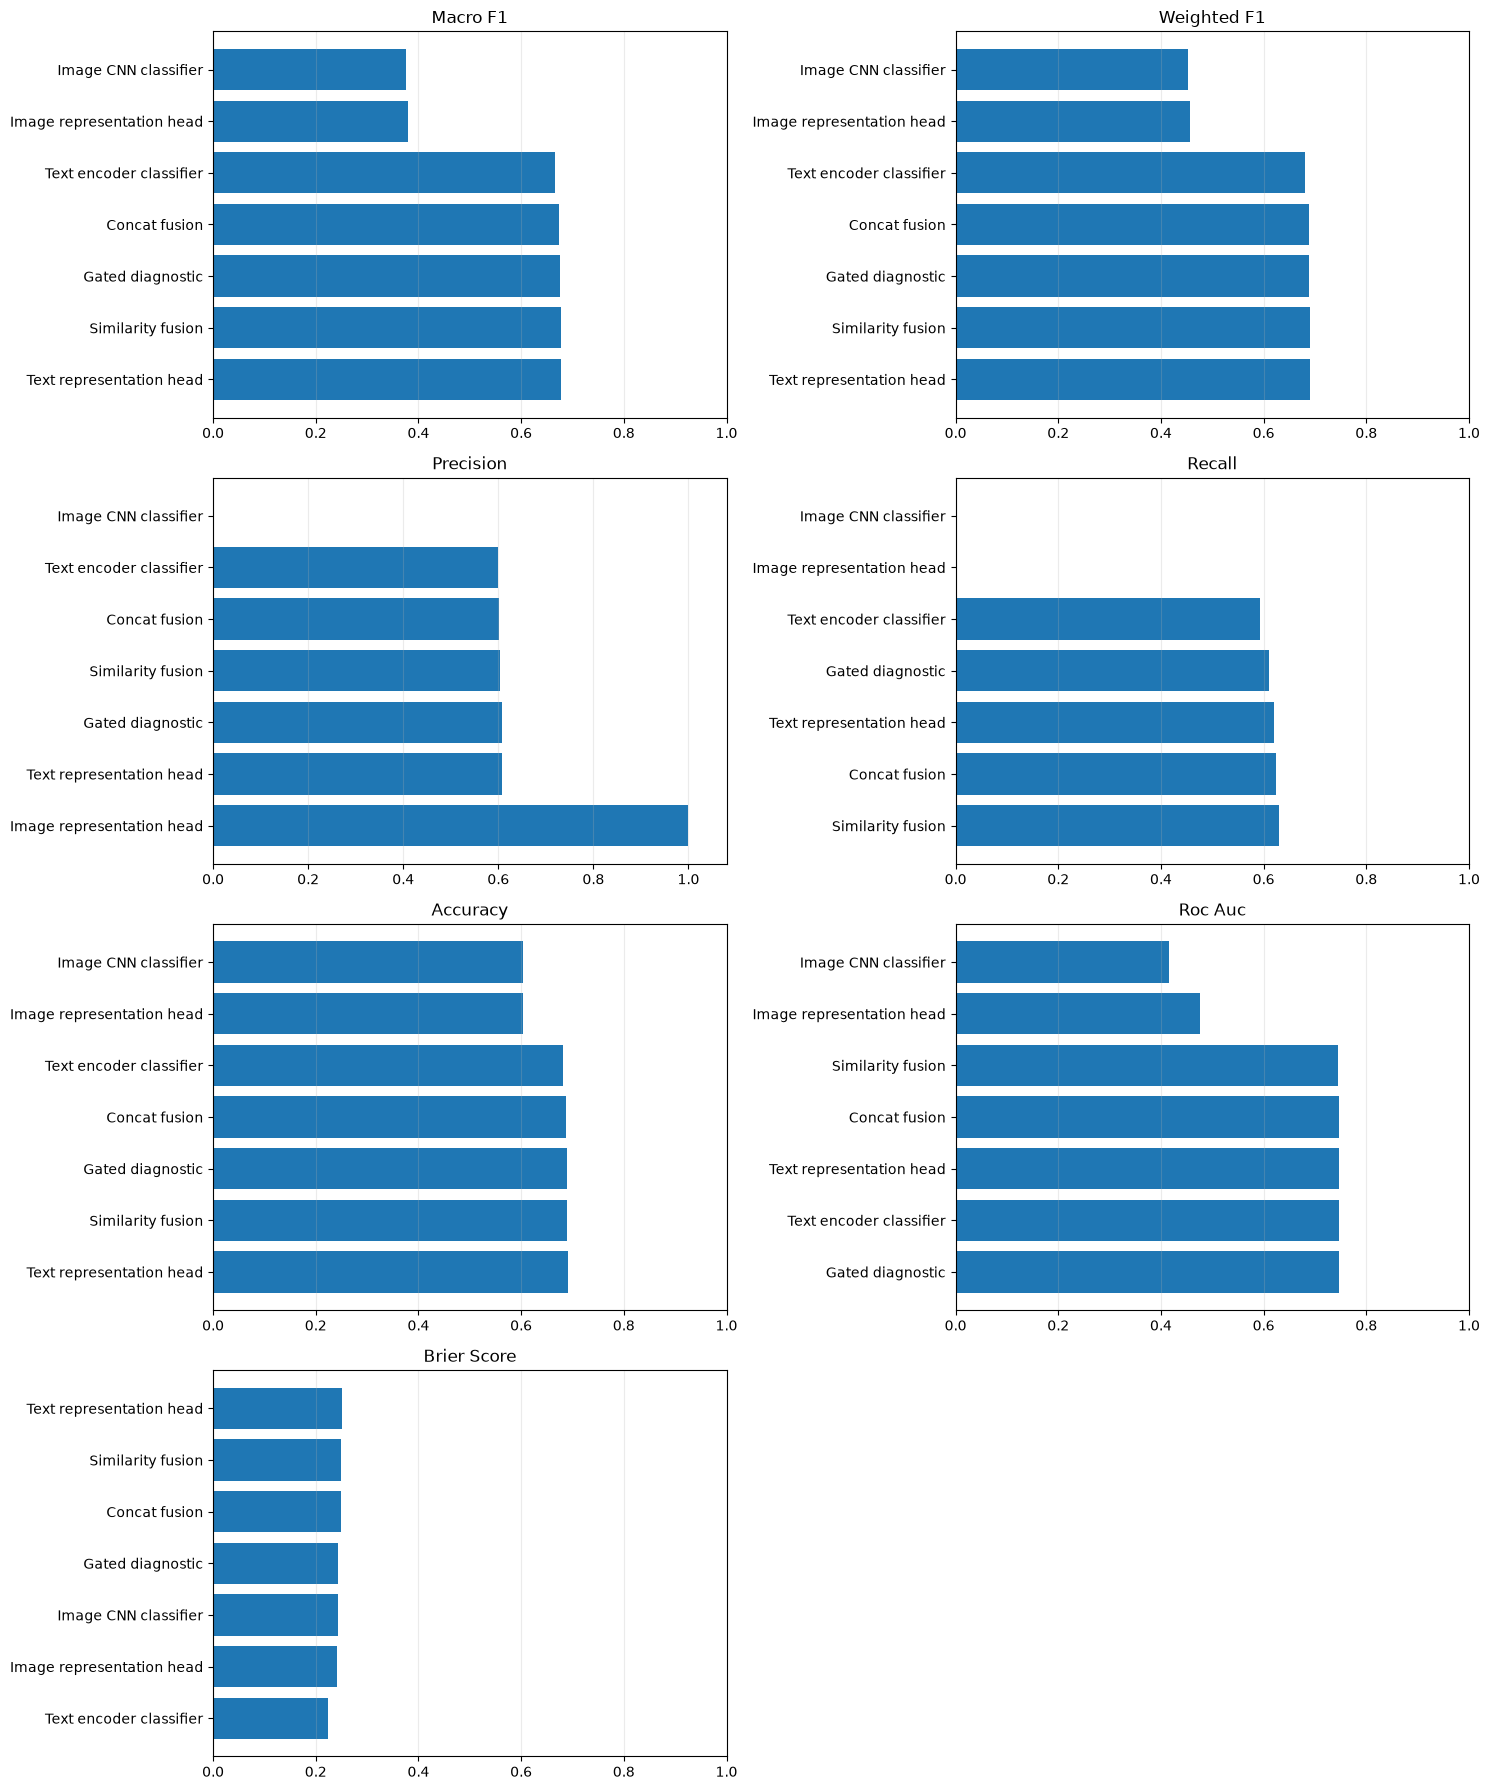

In [6]:
clean_plot = comparison[comparison['manifest'] == 'clean'].copy()
clean_plot['display'] = clean_plot['model'].map(DISPLAY_NAMES)
metrics_to_plot = ['macro_f1', 'weighted_f1', 'precision', 'recall', 'accuracy', 'roc_auc', 'brier_score']

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.ravel()
for ax, metric in zip(axes, metrics_to_plot, strict=False):
    ordered = clean_plot.sort_values(metric, ascending=(metric == 'brier_score'))
    ax.barh(ordered['display'], ordered[metric])
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_xlim(0, max(1.0, ordered[metric].max() * 1.08))
    ax.grid(axis='x', alpha=0.25)
axes[-1].axis('off')
plt.tight_layout()

## ROC Curves

ROC curves use the saved validation probabilities, not hard labels. Higher curves and larger AUC values indicate better ranking ability.

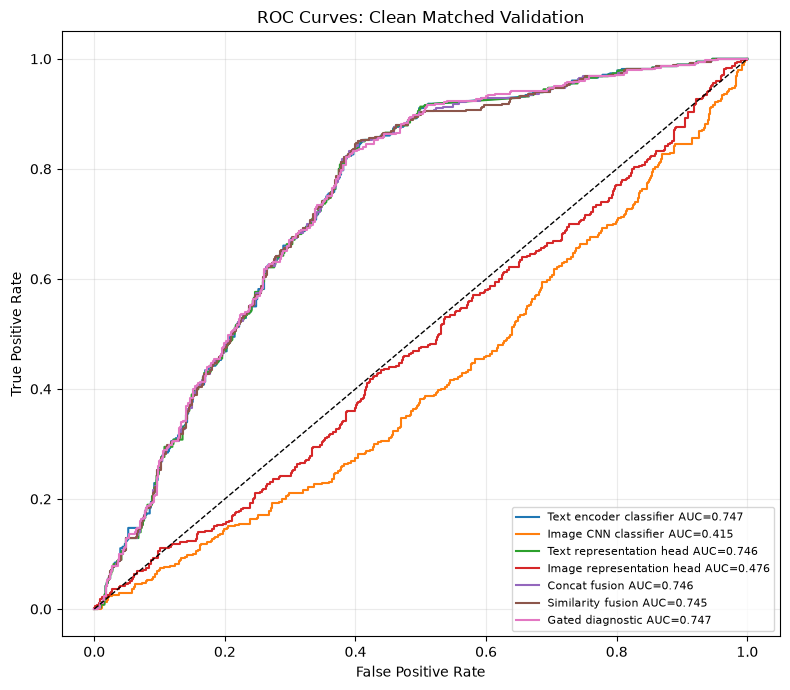

In [7]:
def plot_roc_curves(frame, title):
    labels = frame['2_way_label'].to_numpy(dtype=int)
    plt.figure(figsize=(8, 7))
    for model in MODEL_NAMES:
        scores = frame[f'{model}_score'].to_numpy(dtype=float)
        fpr, tpr = roc_curve_manual(labels, scores)
        auc = binary_classification_metrics(labels, (scores >= 0.5).astype(int), scores)['roc_auc']
        plt.plot(fpr, tpr, label=f'{DISPLAY_NAMES[model]} AUC={auc:.3f}')
    plt.plot([0, 1], [0, 1], linestyle='--', color='black', linewidth=1)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right', fontsize=8)
    plt.grid(alpha=0.25)
    plt.tight_layout()

plot_roc_curves(clean_predictions, 'ROC Curves: Clean Matched Validation')

## Original vs Clean ROC Curves

These curves show how leakage reduction changes model ranking performance.

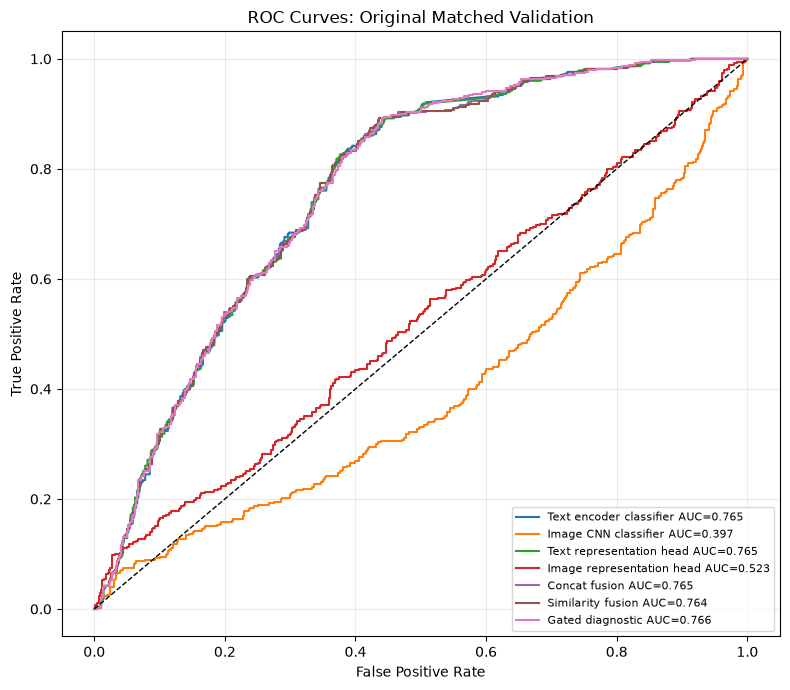

In [8]:
plot_roc_curves(original_predictions, 'ROC Curves: Original Matched Validation')

## Confusion Matrices

Rows are true labels and columns are predicted labels. Label `0` means true/real, and label `1` means fake.

/var/folders/z2/0sxdyr9n42l6xybwfq6w_dz00000gn/T/ipykernel_86664/1607001792.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


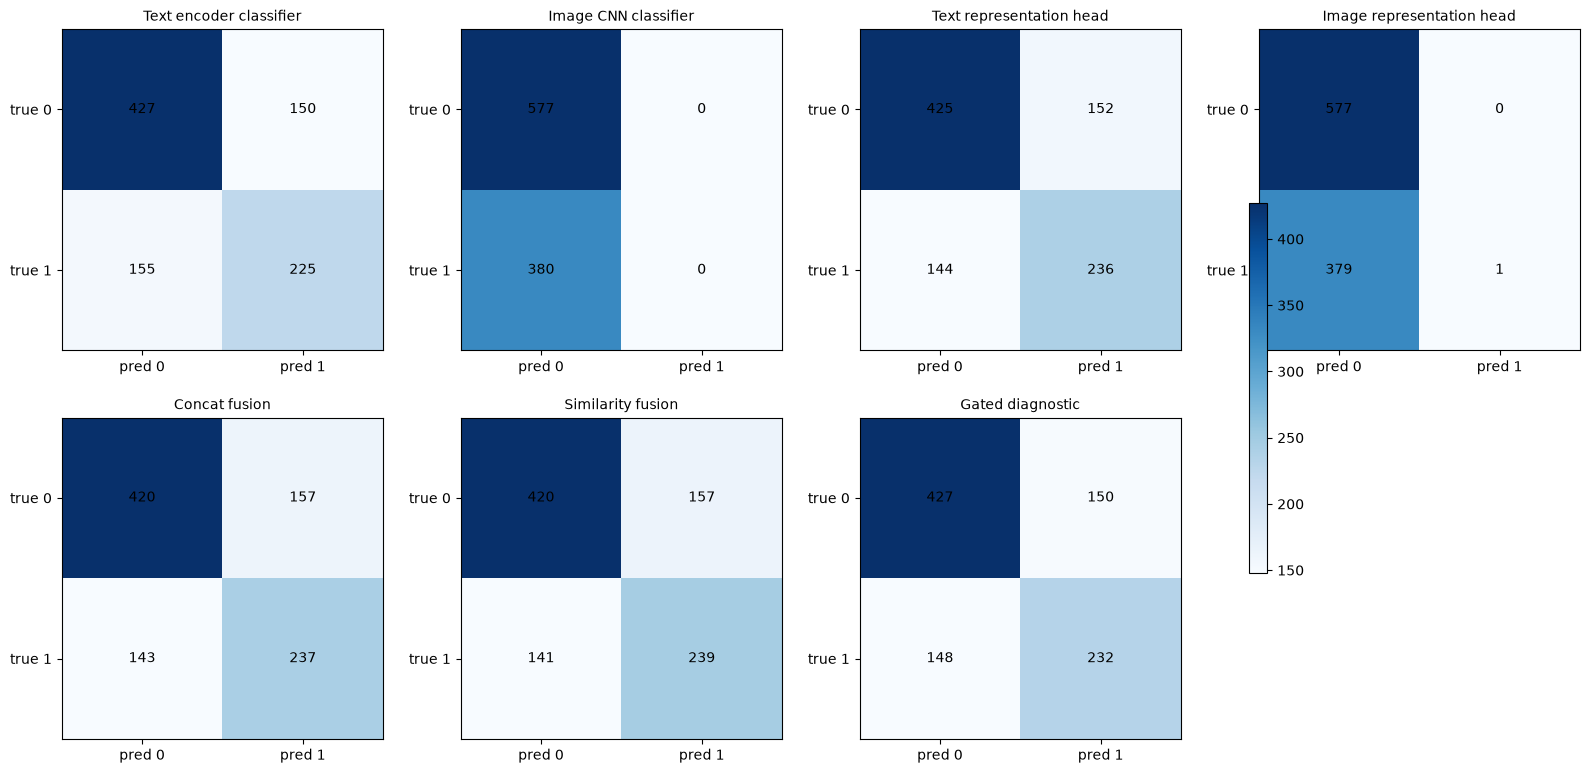

In [9]:
labels = clean_predictions['2_way_label'].to_numpy(dtype=int)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax, model in zip(axes, MODEL_NAMES, strict=False):
    preds = clean_predictions[f'{model}_prediction'].to_numpy(dtype=int)
    cm = confusion_matrix_binary(labels, preds)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(DISPLAY_NAMES[model], fontsize=10)
    ax.set_xticks([0, 1], labels=['pred 0', 'pred 1'])
    ax.set_yticks([0, 1], labels=['true 0', 'true 1'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', color='black')
axes[-1].axis('off')
fig.colorbar(im, ax=axes.tolist(), shrink=0.6)
plt.tight_layout()

## Threshold Curves

The default threshold is `0.5`, but fake-news detection may prefer a different operating point. These curves show precision, recall, Macro F1, and accuracy across thresholds.

,threshold,accuracy,precision,recall,macro_f1,weighted_f1,tn,fp,fn,tp
2,0.15,0.696970,0.584270,0.821053,0.696357,0.699165,355.0,222.0,68.0,312.0
1,0.10,0.690700,0.574468,0.852632,0.690643,0.691508,337.0,240.0,56.0,324.0
3,0.20,0.686520,0.578740,0.773684,0.684882,0.689559,363.0,214.0,86.0,294.0
4,0.25,0.685475,0.582121,0.736842,0.682278,0.688839,376.0,201.0,100.0,280.0
7,0.40,0.687565,0.594848,0.668421,0.679696,0.690031,404.0,173.0,126.0,254.0
5,0.30,0.682341,0.582609,0.705263,0.677521,0.685636,385.0,192.0,112.0,268.0
6,0.35,0.683386,0.586517,0.686842,0.677245,0.686409,393.0,184.0,119.0,261.0
8,0.45,0.684431,0.594660,0.644737,0.674762,0.686306,410.0,167.0,135.0,245.0
9,0.50,0.686520,0.601523,0.623684,0.674623,0.687431,420.0,157.0,143.0,237.0
10,0.55,0.685475,0.604222,0.602632,0.671410,0.685404,427.0,150.0,151.0,229.0


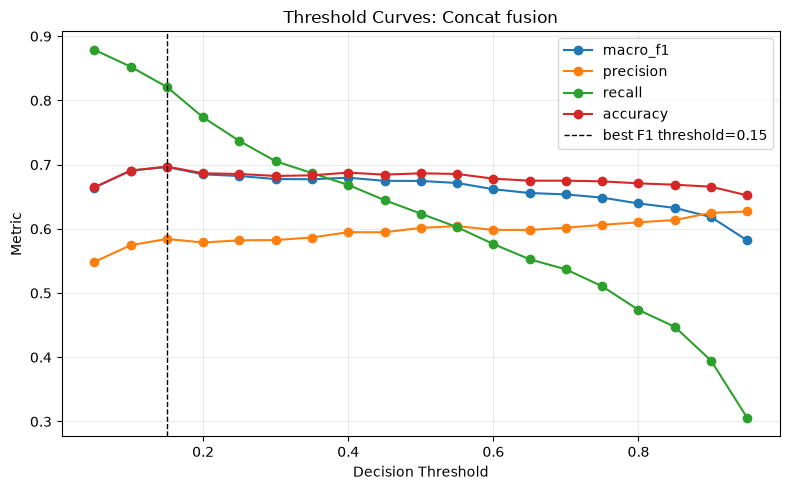

In [10]:
def plot_threshold_curves(frame, model):
    labels = frame['2_way_label'].to_numpy(dtype=int)
    scores = frame[f'{model}_score'].to_numpy(dtype=float)
    thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
    rows = pd.DataFrame(threshold_metrics(labels, scores, thresholds))
    plt.figure(figsize=(8, 5))
    for metric in ['macro_f1', 'precision', 'recall', 'accuracy']:
        plt.plot(rows['threshold'], rows[metric], marker='o', label=metric)
    best = rows.sort_values(['macro_f1', 'accuracy'], ascending=False).iloc[0]
    plt.axvline(best['threshold'], color='black', linestyle='--', linewidth=1, label=f'best F1 threshold={best["threshold"]:.2f}')
    plt.title(f'Threshold Curves: {DISPLAY_NAMES[model]}')
    plt.xlabel('Decision Threshold')
    plt.ylabel('Metric')
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    return rows

concat_thresholds = plot_threshold_curves(clean_predictions, 'concat_fusion')
concat_thresholds.sort_values('macro_f1', ascending=False).head(10)

## Threshold Curves For All Clean Models

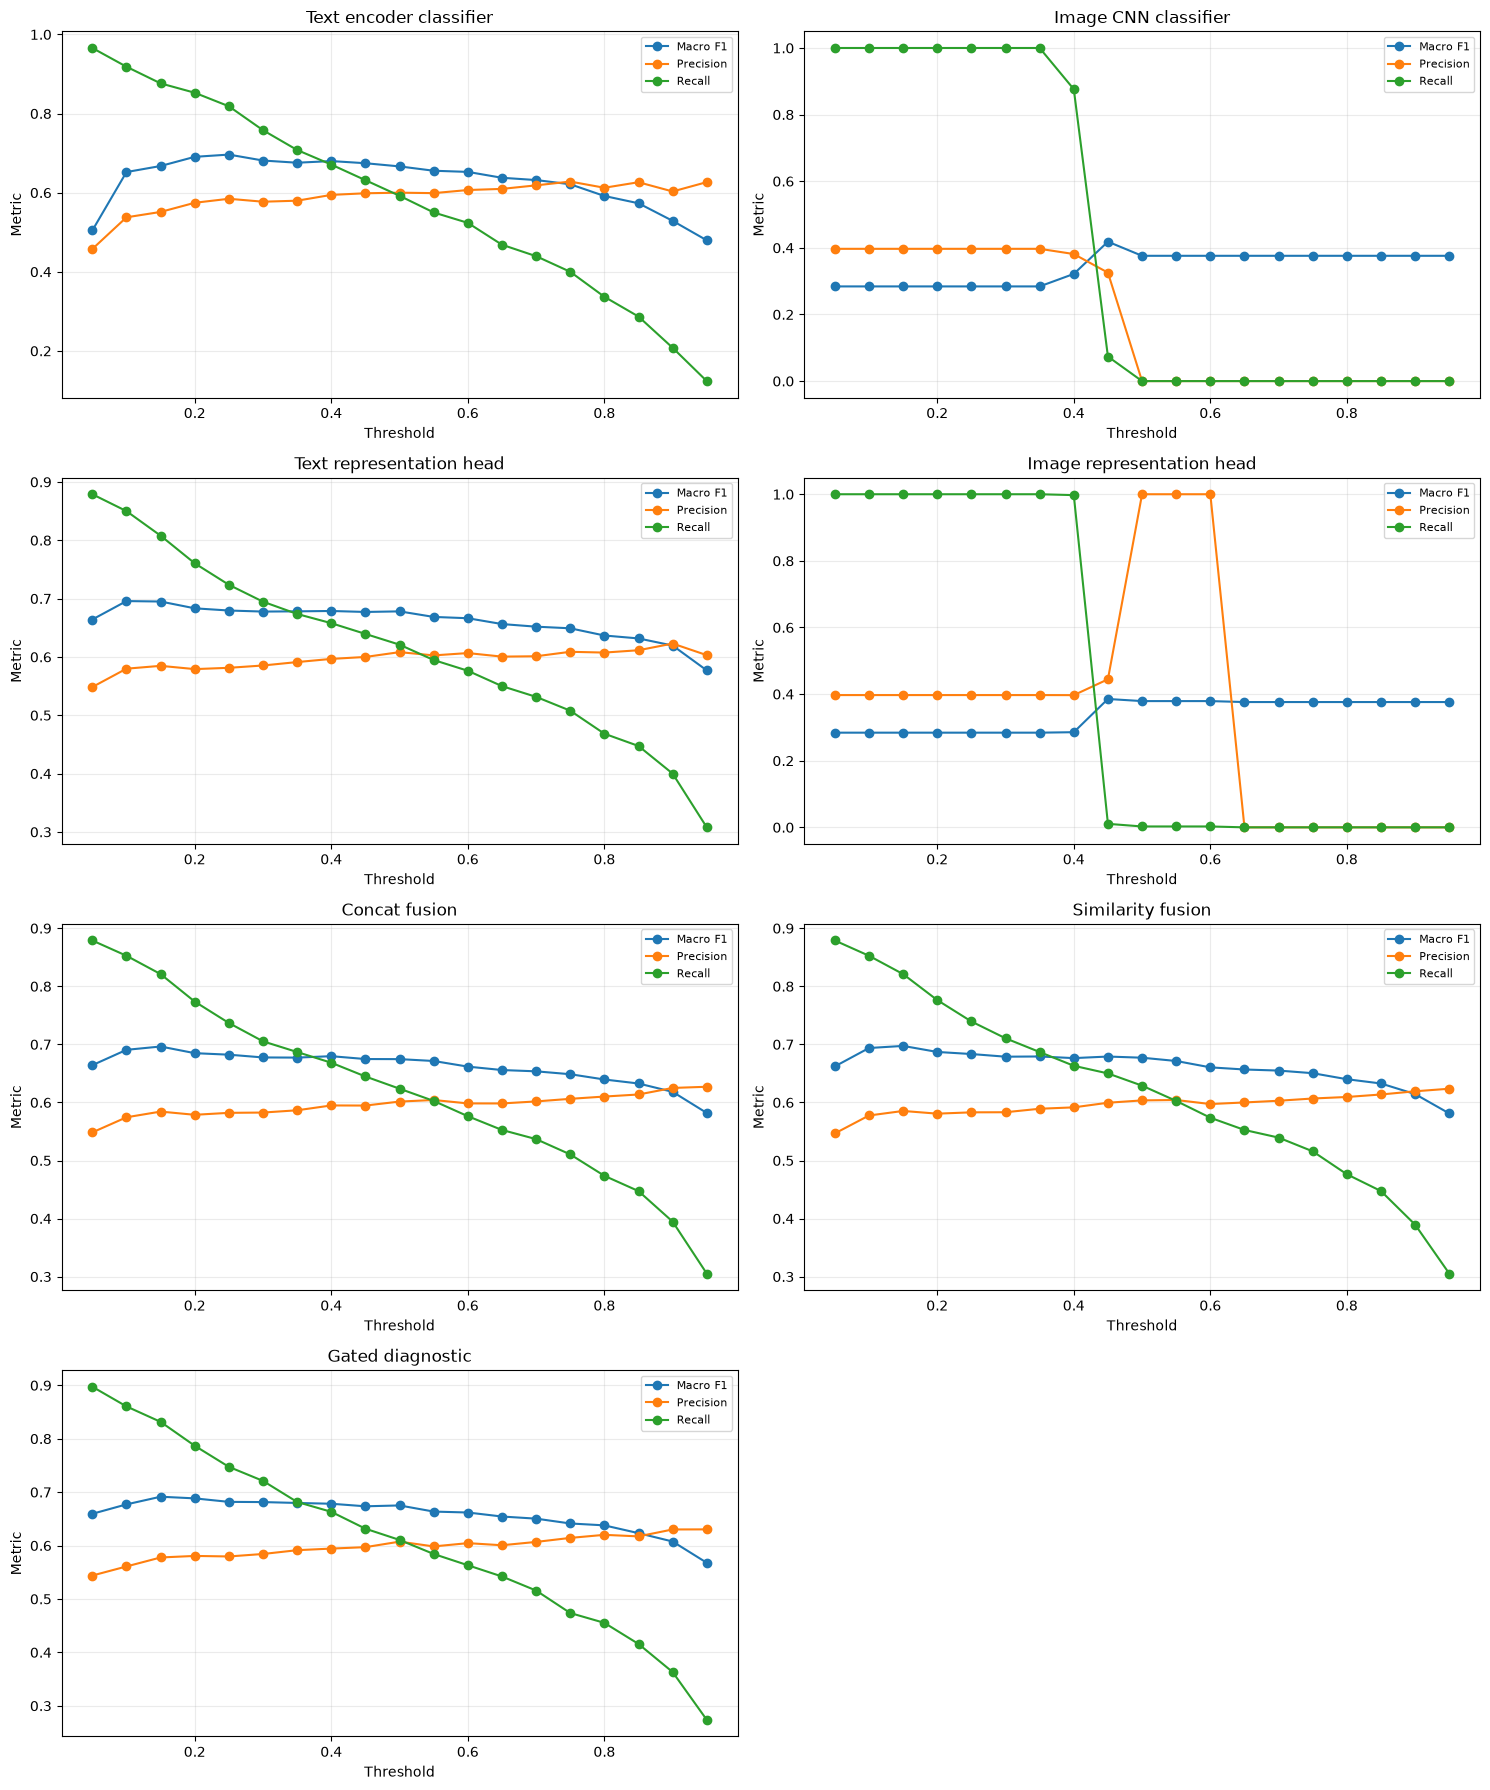

In [11]:
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.ravel()
for ax, model in zip(axes, MODEL_NAMES, strict=False):
    labels = clean_predictions['2_way_label'].to_numpy(dtype=int)
    scores = clean_predictions[f'{model}_score'].to_numpy(dtype=float)
    rows = pd.DataFrame(threshold_metrics(labels, scores, np.round(np.arange(0.05, 1.0, 0.05), 2)))
    ax.plot(rows['threshold'], rows['macro_f1'], marker='o', label='Macro F1')
    ax.plot(rows['threshold'], rows['precision'], marker='o', label='Precision')
    ax.plot(rows['threshold'], rows['recall'], marker='o', label='Recall')
    ax.set_title(DISPLAY_NAMES[model])
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Metric')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[-1].axis('off')
plt.tight_layout()

## Calibration And Reliability

Calibration measures whether predicted probabilities behave like real probabilities. For example, samples predicted around `0.70` should be fake about 70% of the time.

In [12]:
calibration = pd.read_csv(REPORT / 'calibration_metrics.csv')
reliability = pd.read_csv(REPORT / 'reliability_bins.csv')
calibration

,model,temperature,validation_nll,brier,ece_10,ece_15,macro_f1,roc_auc
0,concat_before_temperature,1.00,NaN,0.248963,0.210889,0.210938,0.674623,0.746069
1,concat_after_temperature,3.85,0.594446,0.203217,0.085995,0.085995,0.674623,0.746069


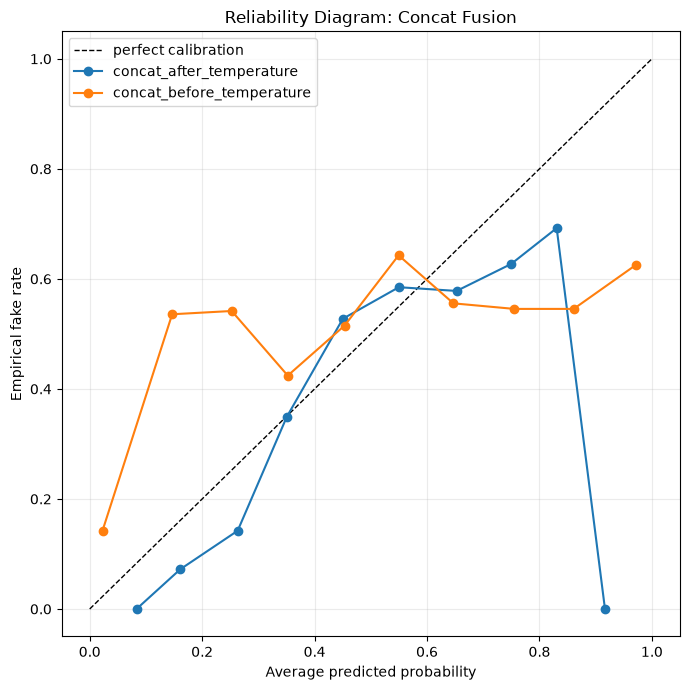

In [13]:
plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], linestyle='--', color='black', linewidth=1, label='perfect calibration')
for model, group in reliability.groupby('model'):
    plt.plot(group['avg_confidence'], group['empirical_positive_rate'], marker='o', label=model)
plt.xlabel('Average predicted probability')
plt.ylabel('Empirical fake rate')
plt.title('Reliability Diagram: Concat Fusion')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

## Abstention / Uncertainty

This evaluates a three-state decision layer: `TRUE`, `UNCERTAIN`, `FAKE`. The classifier abstains near probability `0.5`.

In [14]:
abstention = pd.read_csv(REPORT / 'abstention_results.csv')
abstention

,band,lower_threshold,upper_threshold,coverage,abstention_rate,selective_accuracy,selective_error_rate,selective_macro_f1,decided_count,uncertain_count
0,0.00,0.50,0.50,1.000000,0.000000,0.686520,0.313480,0.674623,957.0,0.0
1,0.05,0.45,0.55,0.881923,0.118077,0.702607,0.297393,0.688270,844.0,113.0
2,0.10,0.40,0.60,0.756531,0.243469,0.738950,0.261050,0.720715,724.0,233.0
3,0.15,0.35,0.65,0.639498,0.360502,0.769608,0.230392,0.745318,612.0,345.0
4,0.20,0.30,0.70,0.512017,0.487983,0.800000,0.200000,0.764608,490.0,467.0
5,0.25,0.25,0.75,0.295716,0.704284,0.784452,0.215548,0.753699,283.0,674.0
6,0.30,0.20,0.80,0.153605,0.846395,0.850340,0.149660,0.804804,147.0,810.0
7,0.35,0.15,0.85,0.050157,0.949843,0.854167,0.145833,0.723457,48.0,909.0
8,0.40,0.10,0.90,0.011494,0.988506,0.727273,0.272727,0.421053,11.0,946.0
9,0.45,0.05,0.95,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,957.0


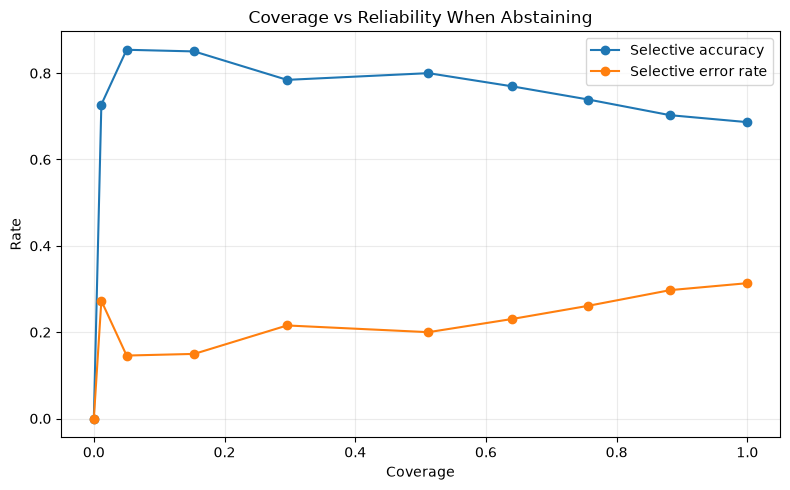

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(abstention['coverage'], abstention['selective_accuracy'], marker='o', label='Selective accuracy')
plt.plot(abstention['coverage'], abstention['selective_error_rate'], marker='o', label='Selective error rate')
plt.xlabel('Coverage')
plt.ylabel('Rate')
plt.title('Coverage vs Reliability When Abstaining')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

## Complementarity And Image Contribution

This checks whether the image branch actually helps the text model.

In [16]:
complementarity = pd.read_csv(REPORT / 'complementarity.csv')
image_contribution = pd.read_csv(REPORT / 'image_contribution.csv')
complementarity

,category,count,percentage,fusion_correct_count,fusion_wrong_count
0,A_text_correct_image_correct,425,0.444096,420,5
1,B_text_correct_image_wrong,236,0.246604,236,0
2,C_text_wrong_image_correct,153,0.159875,0,153
3,D_text_wrong_image_wrong,143,0.149425,1,142
4,net_corrections,-4,-0.004180,1,5


In [17]:
image_contribution

,group,count,mean_delta,mean_abs_delta,median_abs_delta,p95_abs_delta
0,overall,957,0.005164,0.007012,0.001732,0.028939
1,text_correct,661,0.003937,0.005532,0.001244,0.026472
2,text_wrong,296,0.007904,0.010317,0.004419,0.032659
3,fusion_corrected_text_errors,1,0.045997,0.045997,0.045997,0.045997


## Bootstrap Confidence Intervals And Paired Comparison

These results test whether the small fusion-vs-text difference is likely meaningful.

In [18]:
import json

bootstrap = pd.read_csv(REPORT / 'bootstrap_results.csv')
paired = json.loads((REPORT / 'paired_comparison.json').read_text())
bootstrap

,model,ci_low,median,ci_high
0,text_repr_same_head,0.650796,0.678526,0.710823
1,concat_fusion,0.639730,0.674788,0.702740
2,similarity_fusion,0.646882,0.676972,0.707066
3,concat_minus_text,-0.048152,-0.002947,0.033711


In [19]:
paired

{'fusion_model': 'concat_fusion',
 'mcnemar_chi2': 1.5,
 'n01_a_wrong_b_correct': 1.0,
 'n10_a_correct_b_wrong': 5.0,
 'text_model': 'text_repr_same_head'}

## Final Interpretation

The clean leakage-reduced evaluation supports a **TEXT-FIRST** model. The image-only models are weak, multimodal fusion does not improve over the text representation head, image contribution to probability is very small, and bootstrap confidence intervals for fusion minus text cross zero.